In [44]:
import pandas as pd
titanic = pd.read_csv('train.csv')
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [45]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Understand data distributions and class imbalance

Visualize survival rate across different features (e.g., male vs. female, age groups, ticket class)


In [46]:


titanic['Survived'].value_counts()

,count
Survived,
0,549
1,342


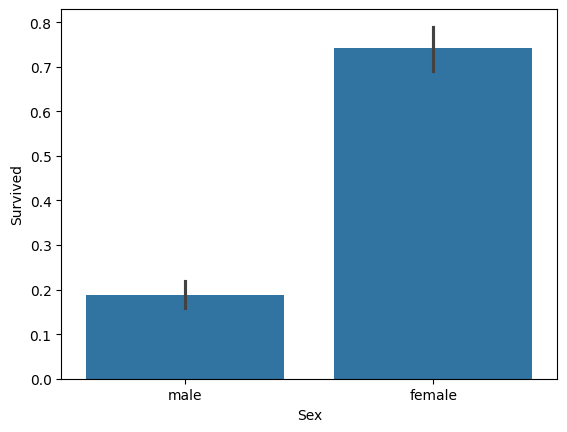

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.barplot(x='Sex',y='Survived', data = titanic)
plt.show()

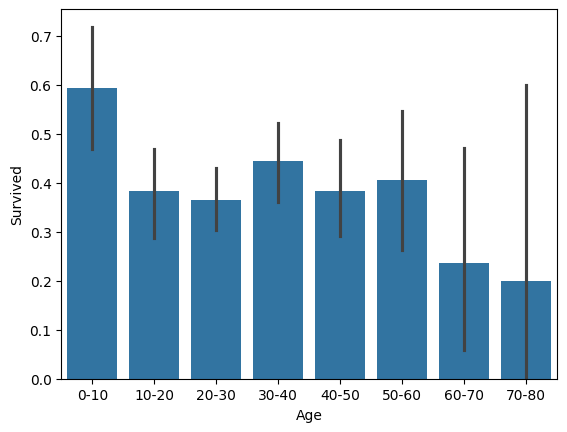

In [48]:
bins = [0,10,20,30,40,50,60,70,80]
labels = ['0-10','10-20','20-30','30-40','40-50','50-60','60-70','70-80']
sns.barplot(x=pd.cut(titanic['Age'],bins=bins,labels=labels),y='Survived', data = titanic)
plt.show()

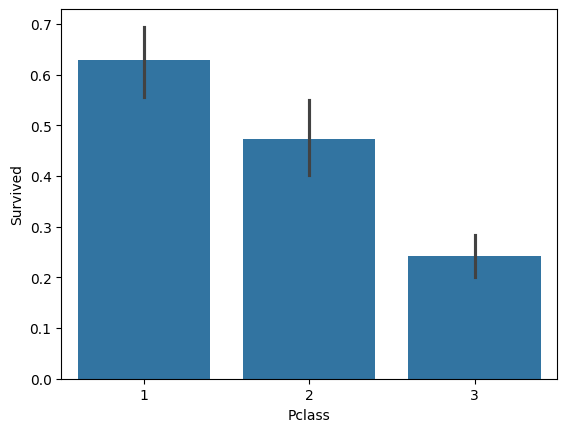

In [49]:
sns.barplot(x='Pclass',y='Survived', data = titanic)
plt.show()

Handle missing values (e.g., fill age using median or predictive imputation)



Encode categorical features (e.g., one-hot or label encoding for Sex, Embarked)



Feature engineering (e.g., extract title from Name, bin Age into groups)

In [50]:
titanic['Age'] = titanic['Age'].fillna(titanic['Age'].median())
titanic['Embarked'] = titanic['Embarked'].fillna(titanic['Embarked'].mode()[0])
titanic['Cabin'] = titanic['Cabin'].fillna('Unknown')

In [51]:
titanic.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [52]:
# import labelencoding
from sklearn.preprocessing import LabelEncoder
LabelEncoder = LabelEncoder()
titanic['Sex'] = LabelEncoder.fit_transform(titanic['Sex'])
titanic['Embarked'] = LabelEncoder.fit_transform(titanic['Embarked'])
titanic['Title'] = titanic['Name'].str.extract(', ([A-Za-z]+)\.', expand=False)
titanic['Title'] = titanic['Title'].fillna('Unknown')
titanic['AgeGroup'] = pd.cut(titanic['Age'],bins=bins,labels=labels)
titanic.head()

<>:6: SyntaxWarning: invalid escape sequence '\.'
<>:6: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_1146/2533818721.py:6: SyntaxWarning: invalid escape sequence '\.'
  titanic['Title'] = titanic['Name'].str.extract(', ([A-Za-z]+)\.', expand=False)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,AgeGroup
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,Unknown,2,Mr,20-30
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,0,Mrs,30-40
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,2,Miss,20-30
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,C123,2,Mrs,30-40
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,Unknown,2,Mr,30-40


Try models like Logistic Regression, Random Forest, or XGBoost



Use cross-validation for model robustness


In [53]:
#import train test split
from sklearn.model_selection import train_test_split
# import logisticregression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
model = LogisticRegression(max_iter=1000)
titanic['Title'] = LabelEncoder.fit_transform(titanic['Title'])
titanic['AgeGroup'] = LabelEncoder.fit_transform(titanic['AgeGroup'])

# drop columns
titanic = titanic.drop(['Name','Ticket','Cabin'], axis=1)
# import scale
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
titanic[['Age','Fare']] = scaler.fit_transform(titanic[['Age','Fare']])
X = titanic.drop('Survived', axis=1)
y = titanic['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)
score = cross_val_score(model, X_train, y_train, cv=5).mean()

Use accuracy, precision, recall, and confusion matrix

In [56]:
metrics = ['accuracy', 'precision', 'recall']
for m in metrics:
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring=m)
    print(f"Mean {m}: {scores.mean():.4f}")

Mean accuracy: 0.8033
Mean precision: 0.7691
Mean recall: 0.6788


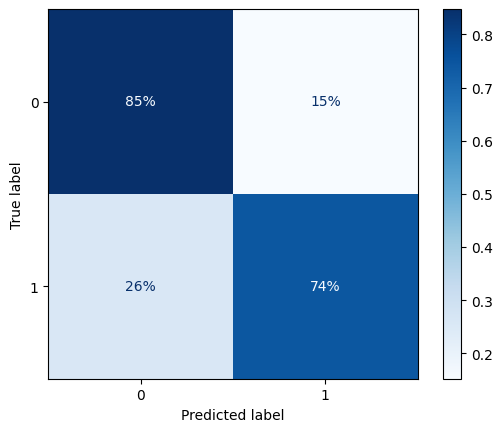

In [64]:

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

y_pred = model.predict(X_test)

# Normalize by true labels to get percentages per row
cm = confusion_matrix(y_test, y_pred, normalize="true")
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=model.classes_
)

# Plot with percentage formatting and a blue colormap
disp.plot(cmap="Blues", values_format=".0%")
plt.show()

Hyperparameter tuning using GridSearchCV

In [66]:
from sklearn.model_selection import GridSearchCV
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(model, param_grid, cv=5).fit(X_train, y_train)


In [68]:
model2 = LogisticRegression(max_iter=1000, C= grid.best_params_['C'])
model2.fit(X_train, y_train)

for m in metrics:
    scores = cross_val_score(model2, X_train, y_train, cv=5, scoring=m)
    print(f"Mean {m}: {scores.mean():.4f}")

Mean accuracy: 0.8033
Mean precision: 0.7691
Mean recall: 0.6788


This shows that the model at first was using the best C

In [69]:
# import randomforest and xgboost
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

RF = RandomForestClassifier()
XG = XGBClassifier()
RF.fit(X_train, y_train)
XG.fit(X_train, y_train)

for m in metrics:
    scores = cross_val_score(RF, X_train, y_train, cv=5, scoring=m)
    print(f"Mean {m}: {scores.mean():.4f}")

for m in metrics:
    scores = cross_val_score(XG, X_train, y_train, cv=5, scoring=m)
    print(f"Mean {m}: {scores.mean():.4f}")

Mean accuracy: 0.8047
Mean precision: 0.7695
Mean recall: 0.6902
Mean accuracy: 0.7950
Mean precision: 0.7663
Mean recall: 0.6677
